# Big Data Storage and Processing - Wind Power Forecasting Pipeline                                                                       
- **Student:** Sebastian Briones 
- **Student Number:** 2026004
- **Module:** Big Data Storage and Processing
- **Dataset:** EirGrid Smart Grid Dashboard - Ireland Electricity Generation (2014–2026)
- **Source:** (https://www.smartgriddashboard.com/)

In [1]:
# Importing libraries
%matplotlib inline
from pyspark.sql.types import *
from pyspark.sql import functions as F
from pyspark.sql.window import Window 
import pyspark.sql.functions as fn   
from pyspark.sql.functions import col, count, when, isnan
import warnings             
warnings.filterwarnings("ignore") 
spark.sparkContext.setLogLevel("ERROR")

## Data Preprocessing

In [2]:
# Load the eirgrid.csv file from HDFS in the within "user/sbriones/ca1/"
# Code based on "Tutorial 4 NN using Pyspark"
df_raw = spark.read.load('hdfs://localhost:9000/user/sbriones/ca1/eirgrid_raw/eirgrid_ALL_2014_2026.csv',
                         format="csv", header="true", 
                         sep=',', inferSchema=True) #inferSchema from tutorial Practice PySpark Exercise 2
df_raw.printSchema()

root
 |-- EffectiveTime: timestamp (nullable = true)
 |-- SYSTEM_DEMAND: double (nullable = true)
 |-- GEN_EXP: double (nullable = true)
 |-- WIND_ACTUAL: double (nullable = true)
 |-- CO2_INTENSITY: double (nullable = true)
 |-- CO2_EMISSIONS: double (nullable = true)
 |-- solar_actual: double (nullable = true)
 |-- solar_forecast: double (nullable = true)
 |-- INTER_EWIC: double (nullable = true)
 |-- INTER_MOYLE: double (nullable = true)
 |-- INTER_NET: double (nullable = true)
 |-- INTER_GRNLK: double (nullable = true)



## Exploratory Data Analysis

In [3]:
df_raw.show(5)

+-------------------+-------------+-------+-----------+-------------+-------------+------------+--------------+----------+-----------+---------+-----------+
|      EffectiveTime|SYSTEM_DEMAND|GEN_EXP|WIND_ACTUAL|CO2_INTENSITY|CO2_EMISSIONS|solar_actual|solar_forecast|INTER_EWIC|INTER_MOYLE|INTER_NET|INTER_GRNLK|
+-------------------+-------------+-------+-----------+-------------+-------------+------------+--------------+----------+-----------+---------+-----------+
|2014-01-01 00:00:00|       3758.0| 3390.0|     1386.0|        383.0|       1346.0|        NULL|          NULL|      NULL|       NULL|     NULL|       NULL|
|2014-01-01 00:15:00|       3724.0| 3359.0|     1348.0|        383.0|       1335.0|        NULL|          NULL|      NULL|       NULL|     NULL|       NULL|
|2014-01-01 00:30:00|       3666.0| 3301.0|     1272.0|        383.0|       1314.0|        NULL|          NULL|      NULL|       NULL|     NULL|       NULL|
|2014-01-01 00:45:00|       3611.0| 3246.0|     1273.0|   

In [4]:
#Check missing values per column                                                                                                                                                                       
# Source: Tutorial 5 (b).ipynb                                                                                                                                                                                                                                                                                                                                                                       
df_raw.agg(*[
    (1 - (fn.count(c) / fn.count('*'))).alias(c + '_missing')
    for c in df_raw.columns
]).show()

+---------------------+---------------------+--------------------+--------------------+---------------------+---------------------+--------------------+----------------------+------------------+-------------------+------------------+-------------------+
|EffectiveTime_missing|SYSTEM_DEMAND_missing|     GEN_EXP_missing| WIND_ACTUAL_missing|CO2_INTENSITY_missing|CO2_EMISSIONS_missing|solar_actual_missing|solar_forecast_missing|INTER_EWIC_missing|INTER_MOYLE_missing| INTER_NET_missing|INTER_GRNLK_missing|
+---------------------+---------------------+--------------------+--------------------+---------------------+---------------------+--------------------+----------------------+------------------+-------------------+------------------+-------------------+
|                  0.0| 0.001184315197668...|0.001184315197668...|0.001184315197668...|  0.02657782068127168|  0.07609560328569254|    0.89269880853422|    0.8917826401737592|0.8099174107741399| 0.8099174107741399|0.8099174107741399| 0.85

Based on the missing values obtained, the following columns are excluded:

| Column | Missing % | Reason |
|---|---|---|
| solar_actual | ~89.3% | Only available from 2025, insufficient history |
| solar_forecast | ~89.2% | Same reason as solar_actual |
| CO2_EMISSIONS | ~7.6% | Redundant with CO2_INTENSITY for this model |
| INTER_EWIC | ~81.0% | Irrelevant for this analysis |
| INTER_MOYLE | ~81.0% | Same as above |
| INTER_NET | ~81.0% | Same as above |
| INTER_GRNLK | ~85.5% | Same as above |

In [5]:
# Select only relevant columns for wind power forecasting
# Inspect columns before cleaning
# solar_actual and solar_forecast are empty for most of the dataset
# columns INTER_EWIC|INTER_MOYLE|INTER_NET|INTER_GRNLK are irrelevant for the analysis
COLS_TO_KEEP = ["EffectiveTime", "SYSTEM_DEMAND", "GEN_EXP", "WIND_ACTUAL", "CO2_INTENSITY"]                                                                          
                                                                                                                                                             
df_selected = df_raw.select(COLS_TO_KEEP)                                                                                                                                                                                                                 
df_selected.show(10) 

+-------------------+-------------+-------+-----------+-------------+
|      EffectiveTime|SYSTEM_DEMAND|GEN_EXP|WIND_ACTUAL|CO2_INTENSITY|
+-------------------+-------------+-------+-----------+-------------+
|2014-01-01 00:00:00|       3758.0| 3390.0|     1386.0|        383.0|
|2014-01-01 00:15:00|       3724.0| 3359.0|     1348.0|        383.0|
|2014-01-01 00:30:00|       3666.0| 3301.0|     1272.0|        383.0|
|2014-01-01 00:45:00|       3611.0| 3246.0|     1273.0|        391.0|
|2014-01-01 01:00:00|       3543.0| 3178.0|     1236.0|        393.0|
|2014-01-01 01:15:00|       3518.0| 3153.0|     1242.0|        396.0|
|2014-01-01 01:30:00|       3423.0| 3132.0|     1205.0|        393.0|
|2014-01-01 01:45:00|       3349.0| 3058.0|     1209.0|        398.0|
|2014-01-01 02:00:00|       3268.0| 2979.0|     1197.0|        398.0|
|2014-01-01 02:15:00|       3206.0| 2960.0|     1216.0|        388.0|
+-------------------+-------------+-------+-----------+-------------+
only showing top 10 

In [6]:
df_selected.summary().show()

+-------+-----------------+-----------------+------------------+------------------+
|summary|    SYSTEM_DEMAND|          GEN_EXP|       WIND_ACTUAL|     CO2_INTENSITY|
+-------+-----------------+-----------------+------------------+------------------+
|  count|           446986|           446986|            446986|            435622|
|   mean|4322.738687565158|4144.746920485205|1293.3869696142608|345.38946150561725|
| stddev| 860.423096864893| 791.152722551858|1001.0592075954738| 131.6331283247744|
|    min|           2176.0|           1925.0|             -59.0|              16.0|
|    25%|           3667.0|           3599.0|             445.0|             238.0|
|    50%|           4381.0|           4080.0|            1065.0|             339.0|
|    75%|           4929.0|           4628.0|            1964.0|             449.0|
|    max|           7497.0|           7774.0|            4713.0|             809.0|
+-------+-----------------+-----------------+------------------+------------

In [7]:
# Checking quantity of observations
df_selected.count()

447516

In [8]:
# Renaming
# Keeping features where Wind Generation is greater or equal zero (from summary above, min WIND_ACTUAL = -59)
# Converting timestamp to proper type and sorting chronologically for time series
df_clean = df_selected \
    .withColumnRenamed("EffectiveTime", "timestamp") \
    .withColumnRenamed("SYSTEM_DEMAND", "System Demand (MW)") \
    .withColumnRenamed("GEN_EXP", "Generation (MW)") \
    .withColumnRenamed("WIND_ACTUAL", "Wind Generation (MW)") \
    .withColumnRenamed("CO2_INTENSITY", "CO2 Intensity (gCO2/kWh)") \
    .withColumn("timestamp",    F.to_timestamp("timestamp")) \
    .dropDuplicates(["timestamp"]) \
    .dropna(subset=["Wind Generation (MW)", "System Demand (MW)", "timestamp"]) \
    .filter(F.col("Wind Generation (MW)") >= 0) \
    .orderBy("timestamp")

In [9]:
# Checking quantity of observations
df_clean.count()

446865

In [10]:
df_clean.show(10)

+-------------------+------------------+---------------+--------------------+------------------------+
|          timestamp|System Demand (MW)|Generation (MW)|Wind Generation (MW)|CO2 Intensity (gCO2/kWh)|
+-------------------+------------------+---------------+--------------------+------------------------+
|2014-01-01 00:00:00|            3758.0|         3390.0|              1386.0|                   383.0|
|2014-01-01 00:15:00|            3724.0|         3359.0|              1348.0|                   383.0|
|2014-01-01 00:30:00|            3666.0|         3301.0|              1272.0|                   383.0|
|2014-01-01 00:45:00|            3611.0|         3246.0|              1273.0|                   391.0|
|2014-01-01 01:00:00|            3543.0|         3178.0|              1236.0|                   393.0|
|2014-01-01 01:15:00|            3518.0|         3153.0|              1242.0|                   396.0|
|2014-01-01 01:30:00|            3423.0|         3132.0|              120

In [11]:
df_clean.summary().show()

+-------+------------------+-----------------+--------------------+------------------------+
|summary|System Demand (MW)|  Generation (MW)|Wind Generation (MW)|CO2 Intensity (gCO2/kWh)|
+-------+------------------+-----------------+--------------------+------------------------+
|  count|            446865|           446865|              446865|                  435504|
|   mean| 4322.776080024169|4144.859572801629|  1293.7387309366363|      345.35808855946215|
| stddev| 860.4369173338257|791.1678220777565|  1000.9664154303737|       131.6327614772798|
|    min|            2176.0|           1925.0|                 0.0|                    16.0|
|    25%|            3667.0|           3599.0|               445.0|                   237.0|
|    50%|            4381.0|           4080.0|              1065.0|                   339.0|
|    75%|            4929.0|           4628.0|              1964.0|                   449.0|
|    max|            7497.0|           7774.0|              4713.0|   

## Feature Engineering
New features are derived from the cleaned dataset to capture temporal patterns in wind generation:

| Feature | Description | Justification |
|---|---|---|
| hour | Hour of the day (0–23) | Captures intra-day demand cycles |
| month | Month of the year (1–12) | Captures seasonal wind patterns |
| day_of_week | Day of the week (1=Sun, 7=Sat) | Captures weekly demand patterns |
| wind_demand_ratio | Wind / System Demand | Measures wind's share of total generation |
| wind_lag_96 | Wind value 96 steps (24h) ago | Captures daily autocorrelation (Shahid et al., 2021) |
| wind_lag_672 | Wind value 672 steps (7 days) ago | Captures weekly seasonality |


In [12]:
# From Practice PySpark Exercise 1 
window_spec = Window.orderBy("timestamp")                                                                                             
                                                                                                                                          
df_features = df_clean \
    .withColumn("hour", F.hour("timestamp")) \
    .withColumn("month", F.month("timestamp")) \
    .withColumn("day_of_week", F.dayofweek("timestamp")) \
    .withColumn("wind_demand_ratio", F.col("Wind Generation (MW)") / F.col("System Demand (MW)")) \
    .withColumn("wind_lag_96", F.lag("Wind Generation (MW)", 96).over(window_spec)) \
    .withColumn("wind_lag_672",F.lag("Wind Generation (MW)", 672).over(window_spec)) \
    .dropna(subset=["wind_lag_96", "wind_lag_672"])# Remove rows without full lag history                                                                                   
                                                                                                                                          
print(f"Rows after feature engineering: {df_features.count()}")                                                                         
df_features.printSchema()

Rows after feature engineering: 446193
root
 |-- timestamp: timestamp (nullable = true)
 |-- System Demand (MW): double (nullable = true)
 |-- Generation (MW): double (nullable = true)
 |-- Wind Generation (MW): double (nullable = true)
 |-- CO2 Intensity (gCO2/kWh): double (nullable = true)
 |-- hour: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- wind_demand_ratio: double (nullable = true)
 |-- wind_lag_96: double (nullable = true)
 |-- wind_lag_672: double (nullable = true)



In [13]:
df_features.show(10)

+-------------------+------------------+---------------+--------------------+------------------------+----+-----+-----------+-------------------+-----------+------------+
|          timestamp|System Demand (MW)|Generation (MW)|Wind Generation (MW)|CO2 Intensity (gCO2/kWh)|hour|month|day_of_week|  wind_demand_ratio|wind_lag_96|wind_lag_672|
+-------------------+------------------+---------------+--------------------+------------------------+----+-----+-----------+-------------------+-----------+------------+
|2014-01-08 00:00:00|            3789.0|         3199.0|              1253.0|                   395.0|   0|    1|          4| 0.3306941145420955|     1831.0|      1386.0|
|2014-01-08 00:15:00|            3678.0|         3161.0|              1250.0|                   398.0|   0|    1|          4|0.33985861881457313|     1841.0|      1348.0|
|2014-01-08 00:30:00|            3592.0|         3088.0|              1205.0|                   390.0|   0|    1|          4|  0.335467706013363|

In [14]:
df_features.summary().show()

+-------+------------------+------------------+--------------------+------------------------+-----------------+------------------+------------------+-------------------+------------------+------------------+
|summary|System Demand (MW)|   Generation (MW)|Wind Generation (MW)|CO2 Intensity (gCO2/kWh)|             hour|             month|       day_of_week|  wind_demand_ratio|       wind_lag_96|      wind_lag_672|
+-------+------------------+------------------+--------------------+------------------------+-----------------+------------------+------------------+-------------------+------------------+------------------+
|  count|            446193|            446193|              446193|                  434832|           446193|            446193|            446193|             446193|            446193|            446193|
|   mean| 4323.001862422763|4145.4257821167075|  1293.6333223515385|       345.2674527173713|11.50228488568848| 6.444159814250784|   4.0008225140242|0.30024352634628954

In [15]:
# Exploratory Data Analysis using Spark aggregations
# Source: Practice PySpark Exercise 1.ipynb

print(f"{'='*55}")
print(f"  AVERAGE WIND GENERATION BY YEAR")
print(f"{'='*55}")
df_features.groupBy(F.year("timestamp").alias("year")) \
    .agg(
        F.count("Wind Generation (MW)").alias("records"),
        F.round(F.mean("Wind Generation (MW)"), 2).alias("avg_wind_MW"),
        F.round(F.max("Wind Generation (MW)"), 2).alias("max_wind_MW"),
        F.round(F.mean("wind_demand_ratio"), 4).alias("avg_wind_share")
    ).orderBy("year").show()

print(f"{'='*55}")
print(f"  AVERAGE WIND GENERATION BY MONTH")
print(f"{'='*55}")
df_features.groupBy("month").agg(
    F.round(F.mean("Wind Generation (MW)"), 2).alias("avg_wind_MW")
).orderBy("month").show(12)

print(f"{'='*55}")
print(f"  AVERAGE WIND GENERATION BY HOUR")
print(f"{'='*55}")
df_features.groupBy("hour").agg(
    F.round(F.mean("Wind Generation (MW)"), 2).alias("avg_wind_MW")
).orderBy("hour").show(24)

  AVERAGE WIND GENERATION BY YEAR


+----+-------+-----------+-----------+--------------+
|year|records|avg_wind_MW|max_wind_MW|avg_wind_share|
+----+-------+-----------+-----------+--------------+
|2014|  34364|     718.23|     2318.0|        0.1868|
|2015|  35036|     939.78|     2608.0|        0.2384|
|2016|  35117|     862.91|     2827.0|        0.2179|
|2017|  34967|    1056.68|     3292.0|        0.2643|
|2018|  35026|    1261.28|     3990.0|        0.3007|
|2019|  35034|    1365.07|     3991.0|        0.3293|
|2020|  35106|    1560.52|     4239.0|        0.3756|
|2021|  34999|    1333.53|     4471.0|        0.3061|
|2022|  34986|    1559.95|     4585.0|        0.3558|
|2023|  35016|    1567.77|     4629.0|        0.3481|
|2024|  35132|     1510.3|     4629.0|        0.3262|
|2025|  35032|    1556.58|     4675.0|        0.3303|
|2026|  26378|    1585.83|     4713.0|        0.3285|
+----+-------+-----------+-----------+--------------+

  AVERAGE WIND GENERATION BY MONTH
+-----+-----------+
|month|avg_wind_MW|
+-----

### Key Findings

**Yearly trend:**
- Wind share grew from 18.7% (2014) to 37.6% (2020), reflecting Ireland's renewable energy expansion
- Average wind generation nearly doubled from 718 MW (2014) to 1,586 MW (2026)

**Seasonal pattern:**
- Winter months (Jan - Feb) produce the highest wind generation
- Summer months (Jul - Aug) are the lowest
- This confirms strong seasonality (key for using LSTM over simpler models)

**Hourly pattern:**
- Wind generation is relatively stable throughout the day
- Suggests wind is not strongly correlated with time-of-day demand peaks

## Machine Learning Model - Spark MLlib Baseline
A Linear Regression model is trained using Spark MLlib as a baseline to compare against the LSTM model developed in the Neural Networks notebook.
This demonstrates Spark's native ML capabilities for distributed model training.

In [16]:
# Baseline Linear Regression using Spark MLlib
# VectorAssembler pattern: Practice PySpark Exercise 2.ipynb
# LinearRegression: Apache Spark MLlib Documentation
# https://spark.apache.org/docs/latest/ml-classification-regression.html#linear-regression

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Define input features
feature_cols = [
    "hour", "month", "day_of_week", "wind_demand_ratio", "wind_lag_96", "wind_lag_672"
]

# Assemble features into a single vector column (required by Spark MLlib)
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_ml = assembler.transform(df_features).select(
    "features", "Wind Generation (MW)", "timestamp"
)

# Temporal train/test split - train on data before 2025, test on 2025+
# Using temporal split (not random) to respect time series structure
df_train = df_ml.filter(F.year("timestamp") < 2025)
df_test  = df_ml.filter(F.year("timestamp") >= 2025)

print(f"  Train set: {df_train.count():,} rows")
print(f"  Test set:  {df_test.count():,} rows")

# Train Linear Regression model
lr = LinearRegression(
    featuresCol="features",
    labelCol="Wind Generation (MW)"
)
lr_model = lr.fit(df_train)

# Generate predictions on test set
predictions = lr_model.transform(df_test)

# Evaluate model performance
evaluator = RegressionEvaluator(
    labelCol="Wind Generation (MW)",
    predictionCol="prediction"
)

rmse = evaluator.setMetricName("rmse").evaluate(predictions)
mae  = evaluator.setMetricName("mae").evaluate(predictions)
r2   = evaluator.setMetricName("r2").evaluate(predictions)

print(f"{'='*50}")
print(f"  SPARK MLLIB - LINEAR REGRESSION RESULTS")
print(f"{'='*50}")
print(f"  RMSE: {rmse:,.2f} MW")
print(f"  MAE:  {mae:,.2f} MW")
print(f"  R²:   {r2:.4f}")
print(f"{'='*50}")
print(f" Baseline for comparison against LSTM.")
print(f"{'='*50}")

# Feature coefficients - shows which features drive predictions most
print("\nFEATURE COEFFICIENTS:")
for i in range(len(feature_cols)):
    print(f"  {feature_cols[i]}: {lr_model.coefficients[i]:.4f}")

  Train set: 384,783 rows
  Test set:  61,410 rows


  SPARK MLLIB - LINEAR REGRESSION RESULTS
  RMSE: 323.38 MW
  MAE:  222.33 MW
  R²:   0.9099
 Baseline for comparison against LSTM.

FEATURE COEFFICIENTS:
  hour: 20.5353
  month: -3.5312
  day_of_week: 5.8192
  wind_demand_ratio: 4047.2466
  wind_lag_96: 0.0673
  wind_lag_672: 0.0393


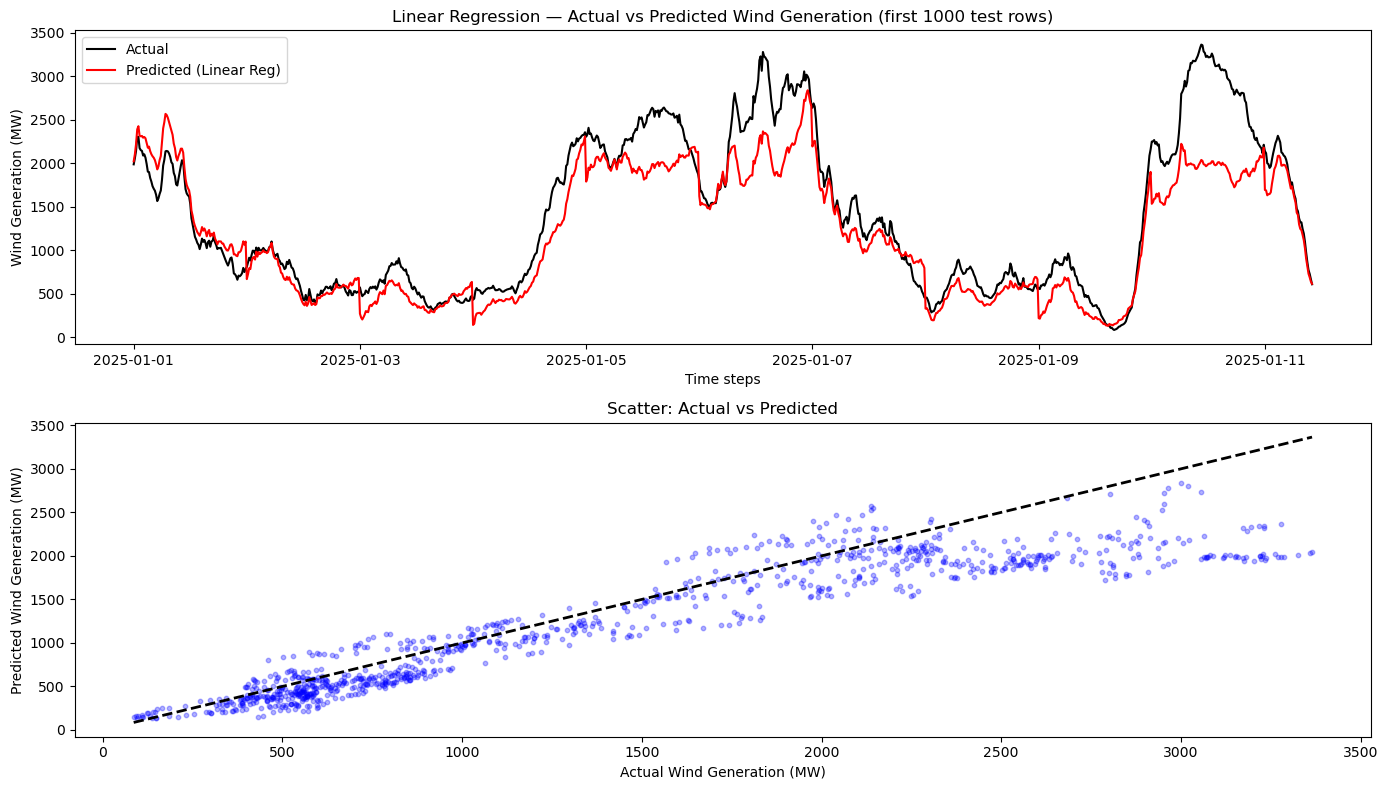

In [17]:
# Visual comparison: predicted vs actual wind generation
# Convert a sample of predictions to pandas for plotting
# Using first 1000 rows of test set for clarity
import matplotlib.pyplot as plt

pred_sample = predictions.select(
    "timestamp", "Wind Generation (MW)", "prediction"
).orderBy("timestamp").limit(1000).toPandas()

actual = pred_sample["Wind Generation (MW)"]
predicted = pred_sample["prediction"]
dates = pred_sample["timestamp"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Line plot: actual vs predicted over time
axes[0].plot(dates, actual, color="black", label="Actual")
axes[0].plot(dates, predicted, color="red", label="Predicted (Linear Reg)")
axes[0].set_title("Linear Regression — Actual vs Predicted Wind Generation (first 1000 test rows)")
axes[0].set_xlabel("Time steps")
axes[0].set_ylabel("Wind Generation (MW)")
axes[0].legend()

# Scatter plot: actual vs predicted
actual = pred_sample["Wind Generation (MW)"]
predicted = pred_sample["prediction"]

axes[1].scatter(actual, predicted, alpha=0.3, color="blue", s=10)
axes[1].plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'k--', lw=2)
axes[1].set_title("Scatter: Actual vs Predicted")
axes[1].set_xlabel("Actual Wind Generation (MW)")
axes[1].set_ylabel("Predicted Wind Generation (MW)")

plt.tight_layout()
plt.show()

#### Model Interpretation

The Linear Regression model achieved R² = 0.9099, with RMSE of 323.38 MW and MAE of 222.33 MW

wind_demand_ratio has the largest raw coefficient (4047), but this reflects its small scale (0–1 range). In absolute contribution terms, wind_lag_96 operating on MW values captures the persistence effect of wind generation, consistent with Shahid et al. (2021) who demonstrated that historical wind values WP(t−24) are the strongest predictors of short-term wind output.

The scatter plot shows significant dispersion around the diagonal, indicating that a linear model cannot capture the non-linear temporal dynamics of wind generation. This justifies the use of LSTM neural networks in the Advanced Data Analytics module.

## Export Pipeline

In [18]:
# Export processed dataset from Spark to pandas for LSTM notebook
# toPandas() bridge pattern - Source: Tutorial 5 - Deep Learning.ipynb
df_pandas = df_features.orderBy("timestamp").toPandas()                                                                                 
                                                                                                                                          
spark.stop()                                                                                                                            
                                                            
df_pandas.to_csv("eirgrid_processed.csv", index=False)                                                                                  
                                                                                                                                                                       
print(f"Shape: {df_pandas.shape}")                        
print(f"Columns: {list(df_pandas.columns)}")                                                                                            
print(df_pandas.head(3)) 

Shape: (446193, 11)
Columns: ['timestamp', 'System Demand (MW)', 'Generation (MW)', 'Wind Generation (MW)', 'CO2 Intensity (gCO2/kWh)', 'hour', 'month', 'day_of_week', 'wind_demand_ratio', 'wind_lag_96', 'wind_lag_672']
            timestamp  System Demand (MW)  Generation (MW)  \
0 2014-01-08 00:00:00              3789.0           3199.0   
1 2014-01-08 00:15:00              3678.0           3161.0   
2 2014-01-08 00:30:00              3592.0           3088.0   

   Wind Generation (MW)  CO2 Intensity (gCO2/kWh)  hour  month  day_of_week  \
0                1253.0                     395.0     0      1            4   
1                1250.0                     398.0     0      1            4   
2                1205.0                     390.0     0      1            4   

   wind_demand_ratio  wind_lag_96  wind_lag_672  
0           0.330694       1831.0        1386.0  
1           0.339859       1841.0        1348.0  
2           0.335468       1833.0        1272.0  
